<a href="https://colab.research.google.com/github/niaparamita/Projek_AkuisisiData/blob/main/notebooks/Tugas_Praktikum_Modul03_Kuliner_Denpasar.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas Praktikum Modul
## Rancangan Akuisisi Data: Peta & Ulasan Warung Kuliner Denpasar

**Nama:** ANAK AGUNG RADHA NOVIANTI (2501010378)

NI PUTU VIRA ARTIKA DEWI (2501010377)

NI MADE NIA PARAMITA (2501010376)

**Kelompok / Kelas:** INFINITY  TEAM

**Isi notebook**
1. Setup
2. Aktivitas Tabel Klasifikasi (Praktikum 6) → `docs/klasifikasi_jenis_data.csv`
3. Tugas 1 — Tabel perbandingan 4 jenis data (≥ 6 atribut)
4. Tugas 2 — Skenario akuisisi + estimasi storage 1 tahun (pertumbuhan 10%/bulan)
5. Ekstraksi metadata 4 jenis data (teks, gambar, audio, spasial)
6. Tugas 3 — Mengapa multimedia tidak disimpan sebagai BLOB di basis data relasional
7. Kesimpulan

## 1. Setup

In [ ]:
import os, json, wave, sqlite3, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 200)

# Folder kerja (struktur repo GitHub)
for folder in ["docs", "data", "output"]:
    os.makedirs(folder, exist_ok=True)
print("Folder siap:", os.listdir("."))

Folder siap: ['.config', 'data', 'docs', 'output', 'sample_data']


## 2. Aktivitas: Tabel Klasifikasi
Baris pertama (`destinasi.csv`) adalah contoh dari soal. Baris lain diisi sesuai karakteristik formatnya, ditambah **3 berkas pilihan sendiri** yang berkaitan dengan skenario kuliner Denpasar (`warung.geojson`, `wawancara_pemilik.mp3`, `foto_warung.jpg`).

In [ ]:
klasifikasi = pd.DataFrame([
    # Berkas, Jenis Data, Cara Membaca, Storage yang Sesuai
    ["destinasi.csv",          "Structured",      "pd.read_csv",                         "Basis data relasional"],
    ["destinasi.xlsx",         "Structured",      "pd.read_excel",                       "Basis data relasional"],
    ["ulasan.json",            "Semi-structured", "json.load / pd.read_json",            "Basis data dokumen (NoSQL, mis. MongoDB)"],
    ["katalog.xml",            "Semi-structured", "xml.etree.ElementTree / pd.read_xml", "Basis data dokumen / XML database"],
    ["contoh.png",             "Unstructured",    "PIL.Image.open",                      "Object storage / file system (path disimpan di DB)"],
    ["teks bebas",             "Unstructured",    "open().read()",                       "File system / search engine (mis. Elasticsearch)"],
    # --- Tambahan (min. 3 berkas pilihan sendiri) ---
    ["warung.geojson",         "Semi-structured (spasial)", "json.load / geopandas.read_file", "Basis data spasial (PostGIS)"],
    ["wawancara_pemilik.mp3",  "Unstructured",    "librosa.load / wave / pydub",         "Object storage (metadata di DB)"],
    ["foto_warung.jpg",        "Unstructured",    "PIL.Image.open",                      "Object storage (path/URL di DB)"],
], columns=["Berkas", "Jenis Data", "Cara Membaca", "Storage yang Sesuai"])

klasifikasi.to_csv("docs/klasifikasi_jenis_data.csv", index=False)
klasifikasi

,Berkas,Jenis Data,Cara Membaca,Storage yang Sesuai
0,destinasi.csv,Structured,pd.read_csv,Basis data relasional
1,destinasi.xlsx,Structured,pd.read_excel,Basis data relasional
2,ulasan.json,Semi-structured,json.load / pd.read_json,"Basis data dokumen (NoSQL, mis. MongoDB)"
3,katalog.xml,Semi-structured,xml.etree.ElementTree / pd.read_xml,Basis data dokumen / XML database
4,contoh.png,Unstructured,PIL.Image.open,Object storage / file system (path disimpan di DB)
5,teks bebas,Unstructured,open().read(),File system / search engine (mis. Elasticsearch)
6,warung.geojson,Semi-structured (spasial),json.load / geopandas.read_file,Basis data spasial (PostGIS)
7,wawancara_pemilik.mp3,Unstructured,librosa.load / wave / pydub,Object storage (metadata di DB)
8,foto_warung.jpg,Unstructured,PIL.Image.open,Object storage (path/URL di DB)


## 3. Tugas 1 — Tabel Perbandingan Karakteristik Empat Jenis Data
Dibandingkan dengan **8 atribut** (syarat minimal 6), dikaitkan dengan skenario *Peta & Ulasan Warung Kuliner Denpasar*.

In [ ]:
perbandingan = pd.DataFrame({
    "Atribut": [
        "1. Contoh dalam skenario",
        "2. Struktur data",
        "3. Format umum",
        "4. Ukuran tipikal per unit",
        "5. Cara membaca (Python)",
        "6. Metadata yang bisa diekstrak",
        "7. Tantangan pengolahan",
        "8. Storage yang sesuai",
    ],
    "Teks": [
        "Ulasan pelanggan warung",
        "Tidak terstruktur (bahasa alami)",
        ".txt, .json, .csv",
        "± 1,5 KB",
        "open(), pandas, json",
        "Jumlah karakter/kata/baris, encoding, bahasa, tanggal tulis",
        "Slang, typo, campuran Indonesia–Bali–Inggris, sentimen ambigu",
        "Basis data relasional (kolom teks) atau NoSQL/search engine",
    ],
    "Gambar": [
        "Foto makanan, fasad warung, materi promosi",
        "Tidak terstruktur (matriks piksel)",
        ".jpg, .png, .webp",
        "± 850 KB",
        "PIL.Image, OpenCV",
        "Resolusi, format, mode warna, EXIF (kamera, waktu, GPS)",
        "Ukuran besar, kualitas foto beragam, butuh pemrosesan visual",
        "Object storage / file system; DB hanya simpan path/URL",
    ],
    "Audio": [
        "Wawancara pemilik warung / testimoni suara",
        "Tidak terstruktur (gelombang sampel)",
        ".mp3, .wav, .m4a",
        "± 5.200 KB (±5 MB)",
        "wave, librosa, pydub",
        "Durasi, sample rate, kanal, bit depth, bitrate",
        "Noise latar (keramaian warung), butuh transkripsi, ukuran besar",
        "Object storage; transkrip disimpan sebagai teks di DB",
    ],
    "Spasial": [
        "Titik koordinat lokasi warung (POI)",
        "Semi-terstruktur (geometri + atribut)",
        ".geojson, .shp, .kml",
        "± 0,3 KB",
        "json, geopandas",
        "Jumlah fitur, tipe geometri, bounding box, sistem koordinat (CRS)",
        "Akurasi GPS, perbedaan CRS, perlu indeks spasial",
        "Basis data spasial (PostGIS) atau GeoJSON",
    ],
})
perbandingan.to_csv("docs/perbandingan_jenis_data.csv", index=False)
perbandingan

,Atribut,Teks,Gambar,Audio,Spasial
0,1. Contoh dalam skenario,Ulasan pelanggan warung,"Foto makanan, fasad warung, materi promosi",Wawancara pemilik warung / testimoni suara,Titik koordinat lokasi warung (POI)
1,2. Struktur data,Tidak terstruktur (bahasa alami),Tidak terstruktur (matriks piksel),Tidak terstruktur (gelombang sampel),Semi-terstruktur (geometri + atribut)
2,3. Format umum,".txt, .json, .csv",".jpg, .png, .webp",".mp3, .wav, .m4a",".geojson, .shp, .kml"
3,4. Ukuran tipikal per unit,"± 1,5 KB",± 850 KB,± 5.200 KB (±5 MB),"± 0,3 KB"
4,5. Cara membaca (Python),"open(), pandas, json","PIL.Image, OpenCV","wave, librosa, pydub","json, geopandas"
5,6. Metadata yang bisa diekstrak,"Jumlah karakter/kata/baris, encoding, bahasa, tanggal tulis","Resolusi, format, mode warna, EXIF (kamera, waktu, GPS)","Durasi, sample rate, kanal, bit depth, bitrate","Jumlah fitur, tipe geometri, bounding box, sistem koordinat (CRS)"
6,7. Tantangan pengolahan,"Slang, typo, campuran Indonesia–Bali–Inggris, sentimen ambigu","Ukuran besar, kualitas foto beragam, butuh pemrosesan visual","Noise latar (keramaian warung), butuh transkripsi, ukuran besar","Akurasi GPS, perbedaan CRS, perlu indeks spasial"
7,8. Storage yang sesuai,Basis data relasional (kolom teks) atau NoSQL/search engine,Object storage / file system; DB hanya simpan path/URL,Object storage; transkrip disimpan sebagai teks di DB,Basis data spasial (PostGIS) atau GeoJSON


## 4. Tugas 2 — Skenario Akuisisi & Estimasi Storage 1 Tahun

### 4.1 Skenario
**Topik:** *Peta & Ulasan Warung Kuliner Denpasar* (dokumentasi + materi marketing).  
Tim mengumpulkan ulasan pelanggan, foto makanan/warung untuk dokumentasi dan konten promosi, wawancara pemilik warung, serta titik lokasi warung pada peta digital.

### 4.2 Asumsi bulan ke-1 dan pertumbuhan
- Akuisisi bulan ke-1 sebagai dasar, lalu **bertambah 10% setiap bulan** selama 12 bulan.
- Rumus bulan ke-n: **Vₙ = V₁ × 1,1^(n−1)**
- Total 12 bulan: **V₁ × (1,1¹² − 1) ÷ 0,1**
- Konversi: 1 GB = 1.024 MB = 1.048.576 KB.
- Cadangan (overhead, backup, versi): **30%**.

In [ ]:
KB_PER_MB = 1024
KB_PER_GB = 1024 * 1024
GROWTH = 0.10
BULAN = 12
CADANGAN = 0.30

# Asumsi bulan ke-1: (jumlah unit, rata-rata ukuran dalam KB)
asumsi = pd.DataFrame({
    "Jenis data":        ["Teks ulasan", "Foto warung & makanan", "Audio wawancara", "Titik spasial POI"],
    "Unit bulan ke-1":   [1000,          300,                     10,                100],
    "Rata-rata (KB)":    [1.5,           850,                     5200,              0.3],
})
asumsi["Total bulan ke-1 (KB)"] = asumsi["Unit bulan ke-1"] * asumsi["Rata-rata (KB)"]
asumsi["Total bulan ke-1 (MB)"] = (asumsi["Total bulan ke-1 (KB)"] / KB_PER_MB).round(3)
asumsi

,Jenis data,Unit bulan ke-1,Rata-rata (KB),Total bulan ke-1 (KB),Total bulan ke-1 (MB)
0,Teks ulasan,1000,1.5,1500.0,1.465
1,Foto warung & makanan,300,850.0,255000.0,249.023
2,Audio wawancara,10,5200.0,52000.0,50.781
3,Titik spasial POI,100,0.3,30.0,0.029


In [ ]:
v1_kb = asumsi["Total bulan ke-1 (KB)"].sum()
print(f"Akuisisi bulan ke-1: {v1_kb:,.1f} KB = {v1_kb/KB_PER_MB:,.2f} MB = {v1_kb/KB_PER_GB:.4f} GB")

# Pertumbuhan per bulan per jenis data (dalam GB)
rows = []
for n in range(1, BULAN + 1):
    faktor = (1 + GROWTH) ** (n - 1)
    row = {"Bulan": f"B{n}", "Faktor": round(faktor, 4)}
    for _, r in asumsi.iterrows():
        row[r["Jenis data"]] = r["Total bulan ke-1 (KB)"] * faktor / KB_PER_GB
    rows.append(row)

bulanan = pd.DataFrame(rows)
jenis_cols = list(asumsi["Jenis data"])
bulanan["Total bulan (GB)"] = bulanan[jenis_cols].sum(axis=1)
bulanan["Kumulatif (GB)"] = bulanan["Total bulan (GB)"].cumsum()
bulanan.round(4).to_csv("docs/estimasi_storage_bulanan.csv", index=False)
bulanan.round(4)

Akuisisi bulan ke-1: 308,530.0 KB = 301.30 MB = 0.2942 GB


,Bulan,Faktor,Teks ulasan,Foto warung & makanan,Audio wawancara,Titik spasial POI,Total bulan (GB),Kumulatif (GB)
0,B1,1.0000,0.0014,0.2432,0.0496,0.0000,0.2942,0.2942
1,B2,1.1000,0.0016,0.2675,0.0546,0.0000,0.3237,0.6179
2,B3,1.2100,0.0017,0.2943,0.0600,0.0000,0.3560,0.9739
3,B4,1.3310,0.0019,0.3237,0.0660,0.0000,0.3916,1.3656
4,B5,1.4641,0.0021,0.3561,0.0726,0.0000,0.4308,1.7963
5,B6,1.6105,0.0023,0.3917,0.0799,0.0000,0.4739,2.2702
6,B7,1.7716,0.0025,0.4308,0.0879,0.0001,0.5213,2.7915
7,B8,1.9487,0.0028,0.4739,0.0966,0.0001,0.5734,3.3649
8,B9,2.1436,0.0031,0.5213,0.1063,0.0001,0.6307,3.9956
9,B10,2.3579,0.0034,0.5734,0.1169,0.0001,0.6938,4.6894


In [ ]:
# Verifikasi dengan rumus deret geometri
total_rumus_gb = (v1_kb * ((1 + GROWTH) ** BULAN - 1) / GROWTH) / KB_PER_GB
total_loop_gb  = bulanan["Total bulan (GB)"].sum()
total_naif_gb  = v1_kb * BULAN / KB_PER_GB
total_cadangan = total_loop_gb * (1 + CADANGAN)

print(f"Total 12 bulan (loop)            : {total_loop_gb:.3f} GB")
print(f"Total 12 bulan (rumus deret)     : {total_rumus_gb:.3f} GB")
print(f"Perhitungan naif 12 x bulan ke-1 : {total_naif_gb:.3f} GB  (SALAH, mengabaikan pertumbuhan)")
print(f"Total + cadangan 30%             : {total_cadangan:.3f} GB")
assert abs(total_rumus_gb - total_loop_gb) < 1e-9

# Rincian per jenis data selama 1 tahun
faktor_total = ((1 + GROWTH) ** BULAN - 1) / GROWTH
rincian = asumsi[["Jenis data", "Unit bulan ke-1", "Rata-rata (KB)"]].copy()
rincian["Total 1 tahun (GB)"] = (asumsi["Total bulan ke-1 (KB)"] * faktor_total / KB_PER_GB).round(3)
rincian["Persentase"] = (rincian["Total 1 tahun (GB)"] / rincian["Total 1 tahun (GB)"].sum() * 100).round(2).astype(str) + " %"
rincian.loc[len(rincian)] = ["TOTAL", "", "", round(total_loop_gb, 3), "100 %"]
rincian.loc[len(rincian)] = ["TOTAL + cadangan 30%", "", "", round(total_cadangan, 3), ""]
rincian.to_csv("docs/estimasi_storage_tahunan.csv", index=False)
rincian

Total 12 bulan (loop)            : 6.292 GB
Total 12 bulan (rumus deret)     : 6.292 GB
Perhitungan naif 12 x bulan ke-1 : 3.531 GB  (SALAH, mengabaikan pertumbuhan)
Total + cadangan 30%             : 8.180 GB


,Jenis data,Unit bulan ke-1,Rata-rata (KB),Total 1 tahun (GB),Persentase
0,Teks ulasan,1000,1.5,0.031,0.49 %
1,Foto warung & makanan,300,850.0,5.200,82.64 %
2,Audio wawancara,10,5200.0,1.060,16.85 %
3,Titik spasial POI,100,0.3,0.001,0.02 %
4,TOTAL,,,6.292,100 %
5,TOTAL + cadangan 30%,,,8.180,


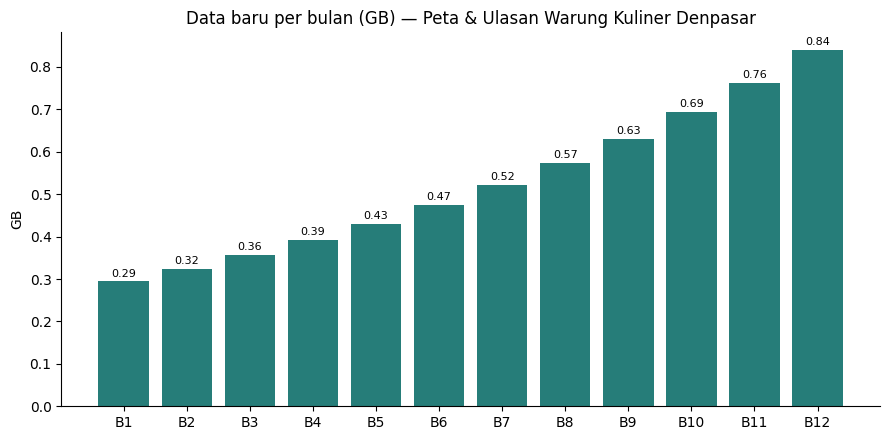

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(bulanan["Bulan"], bulanan["Total bulan (GB)"], color="#267d79")
ax.bar_label(bars, labels=[f"{v:.2f}" for v in bulanan["Total bulan (GB)"]], padding=2, fontsize=8)
ax.set_title("Data baru per bulan (GB) — Peta & Ulasan Warung Kuliner Denpasar")
ax.set_ylabel("GB")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("output/grafik_storage_bulanan.png", dpi=150)
plt.show()

### 4.3 Interpretasi
- Foto mendominasi kebutuhan storage (> 80%), sehingga strategi kompresi/resize foto paling berdampak menekan biaya.
- Teks dan titik spasial nyaris tidak berpengaruh pada ukuran total, namun penting secara analisis.
- Karena data tumbuh 10% per bulan, total setahun jauh lebih besar dari 12 × bulan pertama (faktor ≈ 21,38 vs 12).
- Kapasitas yang perlu disiapkan = **total + cadangan 30%** (lihat hasil di atas).

## 5. Ekstraksi Metadata Empat Jenis Data
Agar notebook bisa dijalankan siapa saja, kita buat **sampel data** (teks, gambar, audio, spasial) lalu mengekstrak metadatanya. Untuk data asli, cukup ganti path berkas di sel sampel (mis. foto warung hasil upload ke Colab).

In [ ]:
# ---------- 5.1 Membuat sampel data ----------
# Teks: ulasan warung
ulasan = [
    "Babi guling di warung ini enak banget, sambalnya mantap! Harga ramah di kantong.",
    "Nasi campur Bali-nya porsi besar, tempatnya bersih. Parkir agak sempit.",
    "Lawar dan sate lilitnya juara, pelayanan cepat. Recommended!",
]
with open("data/ulasan_warung.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(ulasan))

# Gambar: foto sintetis + EXIF sederhana
arr = np.zeros((1080, 1440, 3), dtype=np.uint8)
arr[..., 0] = np.linspace(180, 255, 1440, dtype=np.uint8)
arr[..., 1] = np.linspace(80, 160, 1080, dtype=np.uint8)[:, None]
arr[..., 2] = 60
img = Image.fromarray(arr)
exif = img.getexif()
exif[0x010F] = "Kamera Demo"            # Make
exif[0x0132] = "2026:10:21 10:00:00"    # DateTime
img.save("data/foto_warung.jpg", quality=85, exif=exif)

# Audio: gelombang sinus 5 detik (pengganti rekaman wawancara)
sr, durasi = 22050, 5
t = np.linspace(0, durasi, sr * durasi, endpoint=False)
sinyal = (0.3 * np.sin(2 * np.pi * 440 * t) * 32767).astype(np.int16)
with wave.open("data/wawancara_pemilik.wav", "wb") as w:
    w.setnchannels(1); w.setsampwidth(2); w.setframerate(sr)
    w.writeframes(sinyal.tobytes())

# Spasial: GeoJSON titik warung (koordinat contoh sekitar Denpasar)
geo = {
    "type": "FeatureCollection",
    "crs": {"type": "name", "properties": {"name": "EPSG:4326"}},
    "features": [
        {"type": "Feature", "properties": {"nama": "Warung A", "kategori": "Babi guling"},
         "geometry": {"type": "Point", "coordinates": [115.2167, -8.6500]}},
        {"type": "Feature", "properties": {"nama": "Warung B", "kategori": "Nasi campur"},
         "geometry": {"type": "Point", "coordinates": [115.2300, -8.6700]}},
        {"type": "Feature", "properties": {"nama": "Warung C", "kategori": "Sate lilit"},
         "geometry": {"type": "Point", "coordinates": [115.2050, -8.6600]}},
    ],
}
with open("data/warung.geojson", "w", encoding="utf-8") as f:
    json.dump(geo, f)

print(sorted(os.listdir("data")))

['foto_warung.jpg', 'ulasan_warung.txt', 'warung.geojson', 'wawancara_pemilik.wav']


In [ ]:
# ---------- 5.2 Fungsi ekstraksi metadata ----------
def meta_teks(path):
    raw = open(path, "rb").read()
    teks = raw.decode("utf-8")
    return {
        "Jenis": "Teks", "Berkas": os.path.basename(path),
        "Ukuran (KB)": round(len(raw) / 1024, 3),
        "Metadata": f"{len(teks)} karakter, {len(teks.split())} kata, {len(teks.splitlines())} baris, encoding UTF-8",
    }

def meta_gambar(path):
    with Image.open(path) as im:
        exif = {k: v for k, v in im.getexif().items()}
        return {
            "Jenis": "Gambar", "Berkas": os.path.basename(path),
            "Ukuran (KB)": round(os.path.getsize(path) / 1024, 2),
            "Metadata": f"{im.width}x{im.height} px, format {im.format}, mode {im.mode}, EXIF: {len(exif)} tag (Make={exif.get(0x010F)}, DateTime={exif.get(0x0132)})",
        }

def meta_audio(path):
    with wave.open(path, "rb") as w:
        n, sr_, ch, sw = w.getnframes(), w.getframerate(), w.getnchannels(), w.getsampwidth()
    dur = n / sr_
    bitrate = sr_ * ch * sw * 8 / 1000
    return {
        "Jenis": "Audio", "Berkas": os.path.basename(path),
        "Ukuran (KB)": round(os.path.getsize(path) / 1024, 2),
        "Metadata": f"durasi {dur:.2f} s, {sr_} Hz, {ch} kanal, {sw*8}-bit, bitrate {bitrate:.0f} kbps",
    }

def meta_spasial(path):
    g = json.load(open(path, encoding="utf-8"))
    feats = g["features"]
    xs = [f["geometry"]["coordinates"][0] for f in feats]
    ys = [f["geometry"]["coordinates"][1] for f in feats]
    tipe = sorted({f["geometry"]["type"] for f in feats})
    return {
        "Jenis": "Spasial", "Berkas": os.path.basename(path),
        "Ukuran (KB)": round(os.path.getsize(path) / 1024, 3),
        "Metadata": f"{len(feats)} fitur, geometri {tipe}, CRS {g['crs']['properties']['name']}, bbox [{min(xs)}, {min(ys)}, {max(xs)}, {max(ys)}]",
    }

hasil_meta = pd.DataFrame([
    meta_teks("data/ulasan_warung.txt"),
    meta_gambar("data/foto_warung.jpg"),
    meta_audio("data/wawancara_pemilik.wav"),
    meta_spasial("data/warung.geojson"),
])
hasil_meta.to_csv("docs/metadata_empat_jenis_data.csv", index=False)
hasil_meta

,Jenis,Berkas,Ukuran (KB),Metadata
0,Teks,ulasan_warung.txt,0.208,"213 karakter, 31 kata, 3 baris, encoding UTF-8"
1,Gambar,foto_warung.jpg,32.850,"1440x1080 px, format JPEG, mode RGB, EXIF: 2 tag (Make=Kamera Demo, DateTime=2026:10:21 10:00:00)"
2,Audio,wawancara_pemilik.wav,215.380,"durasi 5.00 s, 22050 Hz, 1 kanal, 16-bit, bitrate 353 kbps"
3,Spasial,warung.geojson,0.535,"3 fitur, geometri ['Point'], CRS EPSG:4326, bbox [115.205, -8.67, 115.23, -8.65]"


## 6. Tugas 3 — Mengapa Multimedia Sebaiknya Tidak Disimpan Langsung sebagai BLOB di Basis Data Relasional?

1. **Ukuran membengkak.** Foto dan audio berukuran ratusan KB sampai MB. Tabel yang berisi BLOB menjadi sangat besar, sehingga backup/restore, replikasi, dan migrasi lambat.
2. **Performa query menurun.** BLOB memenuhi buffer/cache memori basis data sehingga query biasa (filter, join, agregasi) ikut melambat, padahal kolom lain hanya berukuran beberapa byte.
3. **Basis data relasional tidak dirancang untuk konten biner.** Ia unggul pada data terstruktur dan transaksi (ACID), bukan streaming audio/gambar atau pemrosesan konten biner.
4. **Biaya dan skalabilitas.** Storage basis data (SSD, lisensi, IOPS) jauh lebih mahal daripada object storage (mis. S3, Google Cloud Storage), sementara data tumbuh 10% per bulan.
5. **Sulit melayani konten.** Foto harus dibaca dari DB lalu dikirim lewat aplikasi, tidak bisa langsung lewat CDN atau cache browser.
6. **Batas ukuran & fleksibilitas.** Banyak DBMS membatasi ukuran BLOB, dan mengganti/kompres ulang berkas berarti memperbarui baris di database.

**Praktik yang disarankan:** simpan berkas di *object storage / file system*, lalu simpan di tabel hanya **metadata + path/URL** (nama berkas, ukuran, durasi, resolusi, checksum, tanggal, id warung).

Demo kecil di bawah membandingkan kedua pendekatan memakai SQLite.

In [ ]:
# Demo: BLOB vs path pada SQLite
for p in ["data/demo_blob.db", "data/demo_path.db"]:
    if os.path.exists(p): os.remove(p)

foto_files = []
for i in range(30):   # 30 foto tiruan (~ 0,5-1 MB, data acak agar tidak terkompres)
    p = f"data/foto_{i:02d}.bin"
    with open(p, "wb") as f:
        f.write(np.random.default_rng(i).bytes(700 * 1024))
    foto_files.append(p)

# (a) Simpan sebagai BLOB
con = sqlite3.connect("data/demo_blob.db")
con.execute("CREATE TABLE foto (id INTEGER PRIMARY KEY, nama TEXT, isi BLOB)")
for i, p in enumerate(foto_files):
    con.execute("INSERT INTO foto VALUES (?,?,?)", (i, os.path.basename(p), open(p, "rb").read()))
con.commit(); con.close()

# (b) Simpan path + metadata saja
con = sqlite3.connect("data/demo_path.db")
con.execute("CREATE TABLE foto (id INTEGER PRIMARY KEY, nama TEXT, path TEXT, ukuran_kb REAL)")
for i, p in enumerate(foto_files):
    con.execute("INSERT INTO foto VALUES (?,?,?,?)", (i, os.path.basename(p), p, os.path.getsize(p) / 1024))
con.commit(); con.close()

ukuran = {
    "Ukuran database BLOB (KB)": os.path.getsize("data/demo_blob.db") / 1024,
    "Ukuran database path (KB)": os.path.getsize("data/demo_path.db") / 1024,
}
pd.Series(ukuran).round(1)

,0
Ukuran database BLOB (KB),21032.0
Ukuran database path (KB),8.0


In [ ]:
import time
def waktu_query(db, sql, n=20):
    con = sqlite3.connect(db); t0 = time.perf_counter()
    for _ in range(n): con.execute(sql).fetchall()
    con.close(); return (time.perf_counter() - t0) / n * 1000

print(f"SELECT * (BLOB)  : {waktu_query('data/demo_blob.db', 'SELECT * FROM foto'):.3f} ms")
print(f"SELECT * (path)  : {waktu_query('data/demo_path.db', 'SELECT * FROM foto'):.3f} ms")
print("\nDatabase BLOB jauh lebih besar dan membaca baris ikut menarik data biner; "
      "database path tetap kecil karena berkas disimpan di luar DB.")

SELECT * (BLOB)  : 24.031 ms
SELECT * (path)  : 0.058 ms

Database BLOB jauh lebih besar dan membaca baris ikut menarik data biner; database path tetap kecil karena berkas disimpan di luar DB.


## 7. Kesimpulan
- Empat jenis data (teks, gambar, audio, spasial) punya karakteristik, cara baca, dan storage yang berbeda.
- Estimasi akuisisi 1 tahun untuk skenario *Peta & Ulasan Warung Kuliner Denpasar* dengan pertumbuhan 10% per bulan dihitung memakai deret geometri; hasilnya jauh lebih besar dari perhitungan linear. Angka final (termasuk cadangan 30%) ada pada keluaran sel Tugas 2.
- Foto adalah penyumbang storage terbesar, sehingga kompresi dan pengelolaan foto menjadi prioritas.
- Multimedia sebaiknya disimpan di object storage / file system, dan basis data hanya menyimpan metadata serta path/URL.

